# Results Summary: all models on SEP-28k-E and UCLASS

Puts the three models side by side for the Results chapter. Nothing is retrained here: each model
notebook saves its dev/test/UCLASS predictions to `results/*_preds.npz` at the end. Re-run the model
notebooks first if any of those files are missing.

| Model | Notebook | Input |
|---|---|---|
| 1. Wav2Vec 2.0 fine-tune | `Model1_Wav2Vec2.ipynb` | raw waveform into a pretrained transformer |
| 2. DTW + RF | `Model2_DTW_RF.ipynb` | MFCC sequences, DTW distance to class prototypes |
| 3. Static MFCC + RF | `Model.ipynb` | 40 MFCCs averaged over time |

1. Headline metrics on SEP-28k-E and UCLASS
2. Imbalance strategy (and fine-tuning recipe) comparison
3. Per-class F1
4. Paired bootstrap tests between models
5. UCLASS child vs adult, and why the difference is mostly down to label mix

Tables are saved to `results/` as CSV and figures to `results/figures/` as PNG.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score

%run common.ipynb  # shared settings and helper functions

FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
N_BOOT = 2000

# Same order and colour for each model in every figure
MODELS = {
    "Model 1 — Wav2Vec2":       ("model1_wav2vec2_preds.npz",  "#2a78d6"),
    "Model 2 — DTW+RF":         ("model2_dtw_rf_preds.npz",    "#eb6834"),
    "Model 3 — Static MFCC+RF": ("model3_static_rf_preds.npz", "#1baf7a"),
}
COLORS = {name: color for name, (_, color) in MODELS.items()}

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#8c8b86", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "figure.dpi": 110,
})

preds = {}
for name, (fname, _) in MODELS.items():
    path = RESULTS_DIR / fname
    if not path.exists():
        raise FileNotFoundError(f"{path} is missing, run the notebook for {name} first")
    preds[name] = dict(np.load(path))

uclass_meta = load_uclass_meta()

# The paired tests only make sense if every model was scored on the same clips in the same order
ref = preds["Model 1 — Wav2Vec2"]
for name, p in preds.items():
    for split in ["dev", "test", "uclass"]:
        assert np.array_equal(p[f"{split}_true"], ref[f"{split}_true"]), f"{name}: {split} labels don't line up"
assert np.array_equal(ref["uclass_true"], uclass_meta["label"].to_numpy()), "UCLASS metadata doesn't line up"

child_mask = (uclass_meta["age_group"] == "Child (<18)").to_numpy()
adult_mask = (uclass_meta["age_group"] == "Adult (18+)").to_numpy()
print({s: len(ref[f"{s}_true"]) for s in ["dev", "test", "uclass"]},
      f"child={child_mask.sum()} adult={adult_mask.sum()}")

{'dev': 3001, 'test': 3221, 'uclass': 4712} child=1087 adult=3625


## 1. Headline metrics

Averaged over the six classes (macro). AUC-ROC is one-vs-rest from the predicted probabilities,
averaged over the classes present in that evaluation set.

In [2]:
def macro_recall(y_true, y_pred):
    return recall_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0)


def macro_auc(y_true, proba):
    present = [c for c in LABELS if (y_true == c).any() and (y_true != c).any()]
    return np.mean([roc_auc_score(y_true == c, proba[:, c]) for c in present])


def metrics(y_true, y_pred, proba):
    return {
        "macro_f1":        macro_f1(y_true, y_pred),
        "macro_precision": precision_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0),
        "macro_recall":    macro_recall(y_true, y_pred),
        "macro_auc_roc":   macro_auc(y_true, proba),
        "accuracy":        accuracy_score(y_true, y_pred),
    }


# Evaluation set -> (split in the .npz file, which clips to keep)
EVAL_SETS = {
    "SEP-28k-E dev":  ("dev",    None),
    "SEP-28k-E test": ("test",   None),
    "UCLASS (all)":   ("uclass", None),
    "UCLASS child":   ("uclass", child_mask),
    "UCLASS adult":   ("uclass", adult_mask),
}


def select(p, set_name, key):
    """Get one array ("true", "pred" or "proba") for one evaluation set."""
    split, mask = EVAL_SETS[set_name]
    arr = p[f"{split}_{key}"]
    return arr if mask is None else arr[mask]


rows = []
for name, p in preds.items():
    for set_name in EVAL_SETS:
        y_true = select(p, set_name, "true")
        rows.append({"model": name, "eval_set": set_name, "n": len(y_true),
                     **metrics(y_true, select(p, set_name, "pred"), select(p, set_name, "proba"))})

summary = pd.DataFrame(rows)
summary.to_csv(RESULTS_DIR / "summary_metrics.csv", index=False)
summary.pivot(index="model", columns="eval_set", values="macro_f1")[list(EVAL_SETS)].round(3)

eval_set,SEP-28k-E dev,SEP-28k-E test,UCLASS (all),UCLASS child,UCLASS adult
model,,,,,
Model 1 — Wav2Vec2,0.563,0.546,0.180,0.228,0.168
Model 2 — DTW+RF,0.168,0.173,0.099,0.129,0.086
Model 3 — Static MFCC+RF,0.155,0.153,0.065,0.120,0.044


In [3]:
summary.set_index(["eval_set", "model"]).loc[["SEP-28k-E test", "UCLASS (all)"]].round(3)

n  macro_f1  macro_precision  \
eval_set       model                                                       
SEP-28k-E test Model 1 — Wav2Vec2        3221     0.546            0.552   
               Model 2 — DTW+RF          3221     0.173            0.194   
               Model 3 — Static MFCC+RF  3221     0.153            0.208   
UCLASS (all)   Model 1 — Wav2Vec2        4712     0.180            0.201   
               Model 2 — DTW+RF          4712     0.099            0.162   
               Model 3 — Static MFCC+RF  4712     0.065            0.108   

                                         macro_recall  macro_auc_roc  accuracy  
eval_set       model                                                            
SEP-28k-E test Model 1 — Wav2Vec2               0.552          0.849     0.641  
               Model 2 — DTW+RF                 0.196          0.547     0.218  
               Model 3 — Static MFCC+RF         0.197          0.567     0.217  
UCLASS (all)   Model 1 — Wav2Vec2               0.289          0.581     0.247  
               Model 2 — DTW+RF                 0.165          0.502     0.122  
               Model 3 — Static MFCC+RF         0.160          0.447     0.062

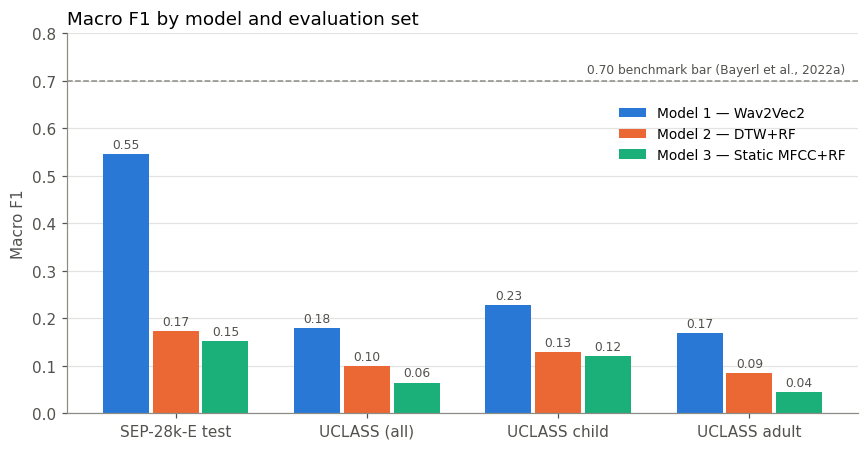

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.2))
sets = ["SEP-28k-E test", "UCLASS (all)", "UCLASS child", "UCLASS adult"]
width = 0.26
x = np.arange(len(sets))
for i, name in enumerate(preds):
    vals = summary[summary.model == name].set_index("eval_set").loc[sets, "macro_f1"]
    bars = ax.bar(x + (i - 1) * width, vals, width - 0.02, color=COLORS[name], label=name)
    ax.bar_label(bars, fmt="%.2f", fontsize=8, color="#52514e", padding=2)
ax.axhline(0.70, color="#8c8b86", linestyle="--", linewidth=1)
ax.text(len(sets) - 0.5, 0.71, "0.70 benchmark bar (Bayerl et al., 2022a)", ha="right",
        va="bottom", fontsize=8, color="#52514e")
ax.set_xticks(x, sets)
ax.set_ylabel("Macro F1")
ax.set_ylim(0, 0.8)
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, fontsize=9, loc="upper right", bbox_to_anchor=(1, 0.84))
ax.set_title("Macro F1 by model and evaluation set", loc="left")
plt.tight_layout()
plt.savefig(FIG_DIR / "macro_f1_by_model.png", dpi=200)
plt.show()

## 2. Imbalance strategy and fine-tuning recipe

Every model was trained with class weighting, undersampling and oversampling, and the one with the
best **dev** macro F1 was used for test and UCLASS. For Wav2Vec 2.0 each strategy was also tried with
three fine-tuning recipes (v1, v2, v3; see `Model1_Wav2Vec2.ipynb` section 5). Test and UCLASS were
not used for any of these choices.

In [5]:
strategy_rows = []
for name, p in preds.items():
    for s, f1 in zip(p["strategy_names"], p["strategy_dev_f1"]):
        recipe, strategy = str(s).split("/") if "/" in str(s) else ("—", str(s))
        strategy_rows.append({"model": name, "recipe": recipe, "strategy": strategy,
                              "dev_macro_f1": float(f1), "selected": str(s) == str(p["best_strategy"])})
strategies = pd.DataFrame(strategy_rows)
strategies.to_csv(RESULTS_DIR / "imbalance_strategy_comparison.csv", index=False)

table = strategies.pivot_table(index=["model", "recipe"], columns="strategy", values="dev_macro_f1").round(4)
table["selected"] = (strategies[strategies.selected].set_index(["model", "recipe"])["strategy"]
                     .reindex(table.index).fillna(""))
table

strategy                         class_weighted  oversampling  undersampling  \
model                    recipe                                                
Model 1 — Wav2Vec2       v1              0.5559        0.5632         0.5222   
                         v2              0.2560        0.2091         0.2017   
                         v3              0.5601        0.5465         0.5499   
Model 2 — DTW+RF         —               0.1525        0.1675         0.1679   
Model 3 — Static MFCC+RF —               0.1152        0.1358         0.1554   

strategy                              selected  
model                    recipe                 
Model 1 — Wav2Vec2       v1       oversampling  
                         v2                     
                         v3                     
Model 2 — DTW+RF         —       undersampling  
Model 3 — Static MFCC+RF —       undersampling

## 3. Per-Class F1

Which stuttering types each model can and cannot detect, in-corpus and cross-corpus.

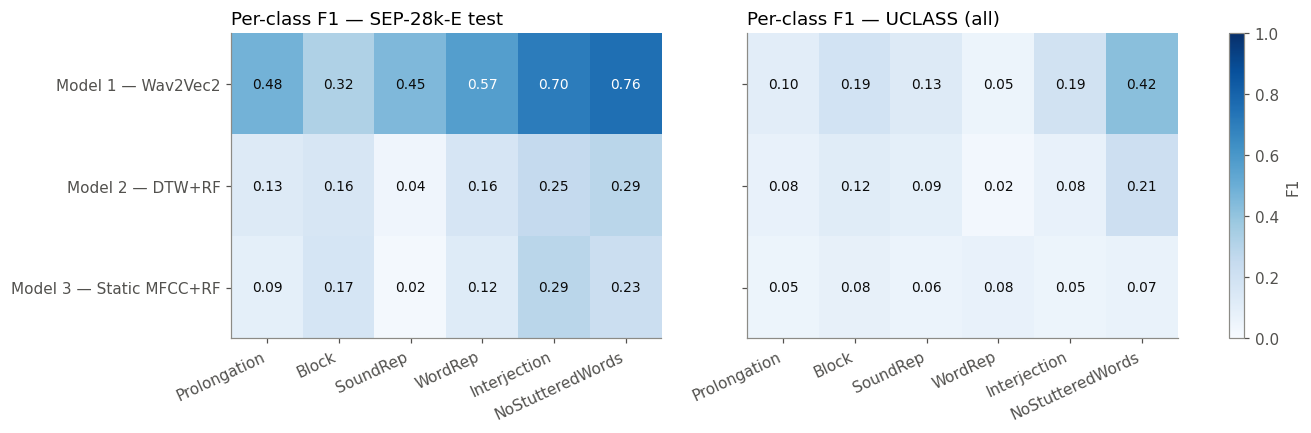

,,Prolongation,Block,SoundRep,WordRep,Interjection,NoStutteredWords
eval_set,model,,,,,,
SEP-28k-E test,Model 1 — Wav2Vec2,0.478,0.323,0.450,0.567,0.703,0.755
UCLASS (all),Model 1 — Wav2Vec2,0.104,0.186,0.127,0.054,0.189,0.423
SEP-28k-E test,Model 2 — DTW+RF,0.130,0.163,0.040,0.164,0.253,0.286
UCLASS (all),Model 2 — DTW+RF,0.076,0.117,0.091,0.024,0.077,0.212
SEP-28k-E test,Model 3 — Static MFCC+RF,0.094,0.168,0.020,0.121,0.288,0.226
UCLASS (all),Model 3 — Static MFCC+RF,0.051,0.080,0.062,0.076,0.053,0.067


In [6]:
per_class = []
for name, p in preds.items():
    for set_name in ["SEP-28k-E test", "UCLASS (all)"]:
        f1s = f1_score(select(p, set_name, "true"), select(p, set_name, "pred"),
                       labels=LABELS, average=None, zero_division=0)
        per_class.append({"model": name, "eval_set": set_name, **dict(zip(CLASS_NAMES, f1s))})
per_class = pd.DataFrame(per_class)
per_class.to_csv(RESULTS_DIR / "per_class_f1.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, set_name in zip(axes, ["SEP-28k-E test", "UCLASS (all)"]):
    mat = per_class[per_class.eval_set == set_name].set_index("model")[CLASS_NAMES]
    im = ax.imshow(mat.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for (r, c), v in np.ndenumerate(mat.values):
        ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="white" if v > 0.55 else "#0b0b0b")
    ax.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=25, ha="right")
    ax.set_yticks(range(len(mat)), mat.index)
    ax.grid(False)
    ax.set_title(f"Per-class F1 — {set_name}", loc="left")
fig.colorbar(im, ax=axes, fraction=0.025, label="F1")
plt.savefig(FIG_DIR / "per_class_f1.png", dpi=200, bbox_inches="tight")
plt.show()
per_class.set_index(["eval_set", "model"]).round(3)

## 4. Paired bootstrap tests between models

All models are scored on the same clips, so differences are tested with a **paired** bootstrap:
each resample uses the same clips for both models and recomputes the difference in macro F1. The
95% CI is the 2.5th-97.5th percentile of those differences. The two-sided p-value is twice the
smaller share of differences on either side of zero (with a minimum of 1/`N_BOOT`).

In [7]:
def paired_bootstrap(y_true, pred_a, pred_b, n_boot=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    diffs = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        diffs[b] = macro_f1(y_true[idx], pred_a[idx]) - macro_f1(y_true[idx], pred_b[idx])
    point = macro_f1(y_true, pred_a) - macro_f1(y_true, pred_b)
    low, high = np.percentile(diffs, [2.5, 97.5])
    p = max(2 * min((diffs <= 0).mean(), (diffs >= 0).mean()), 1 / n_boot)
    return point, low, high, min(p, 1.0)


m1, m2, m3 = preds
short = {name: name.split(" —")[0] for name in preds}
test_rows = []
for set_name in ["SEP-28k-E test", "UCLASS (all)", "UCLASS child", "UCLASS adult"]:
    y_true = select(ref, set_name, "true")
    for a, b in [(m1, m3), (m2, m3), (m1, m2)]:
        d, low, high, pval = paired_bootstrap(y_true, select(preds[a], set_name, "pred"),
                                              select(preds[b], set_name, "pred"))
        test_rows.append({"eval_set": set_name, "comparison": f"{short[a]} − {short[b]}",
                          "delta_macro_f1": d, "ci95_low": low, "ci95_high": high, "p_value": pval})
paired = pd.DataFrame(test_rows)
paired.to_csv(RESULTS_DIR / "paired_bootstrap_tests.csv", index=False)
paired.round(4)

,eval_set,comparison,delta_macro_f1,ci95_low,ci95_high,p_value
0,SEP-28k-E test,Model 1 − Model 3,0.3933,0.3699,0.4163,0.0005
1,SEP-28k-E test,Model 2 − Model 3,0.0200,0.0025,0.0380,0.0250
2,SEP-28k-E test,Model 1 − Model 2,0.3733,0.3501,0.3953,0.0005
3,UCLASS (all),Model 1 − Model 3,0.1156,0.1005,0.1300,0.0005
4,UCLASS (all),Model 2 − Model 3,0.0345,0.0206,0.0469,0.0005
5,UCLASS (all),Model 1 − Model 2,0.0811,0.0684,0.0943,0.0005
6,UCLASS child,Model 1 − Model 3,0.1071,0.0760,0.1363,0.0005
7,UCLASS child,Model 2 − Model 3,0.0090,-0.0192,0.0369,0.5530
8,UCLASS child,Model 1 − Model 2,0.0981,0.0662,0.1280,0.0005
9,UCLASS adult,Model 1 − Model 3,0.1242,0.1072,0.1415,0.0005


## 5. UCLASS child vs adult, and the label-mix problem

Every model gets a *higher* macro F1 on UCLASS children than on adults. Taken at face value that
would mean the models generalise better to children, which would be odd for models trained only on
adult podcasts. But macro F1 depends on how common each class is, not just on how good the model is,
and the two subgroups have very different label mixes (5a). F1's precision term goes up when a class
is common and collapses when it is rare. WordRep, for example, is under 0.5% of adult clips. So the
label mix alone can move a subgroup's macro F1 even if the model is equally good on both.

Four checks to separate label mix from real skill:

- **5a. Label distribution** of each subgroup.
- **5b. Matching the label mix.** Adult clips are resampled within each true class so their class
  proportions and size match the child subgroup (2000 draws). This estimates the adult macro F1 *if
  adults had the children's label mix*. If that closes most of the gap, the gap is label mix, not age.
- **5c. Macro recall** (balanced accuracy). Recall is worked out within each true class, so it
  doesn't depend on how common the classes are. A real child advantage should still show up here.
- **5d. Chance baseline.** A "model" that ignores the audio and guesses at random, using the real
  model's own prediction frequencies. Its macro F1 in each subgroup is how much score the label mix
  gives you for free.

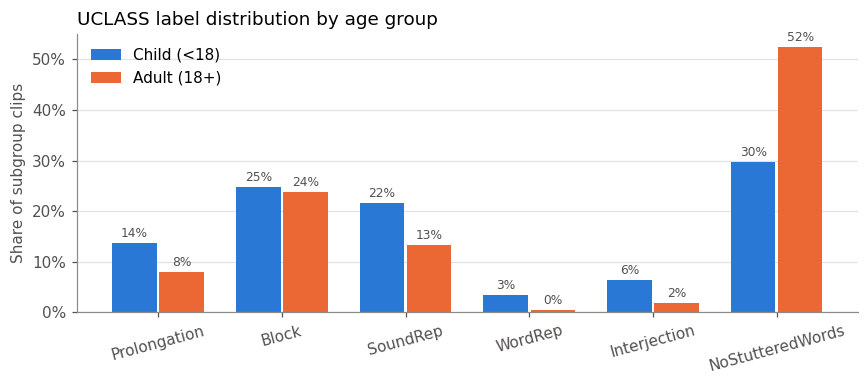

,child_n,adult_n,child_share,adult_share
Prolongation,150,293,0.138,0.081
Block,270,862,0.248,0.238
SoundRep,236,484,0.217,0.134
WordRep,38,16,0.035,0.004
Interjection,70,71,0.064,0.020
NoStutteredWords,323,1899,0.297,0.524


In [8]:
y_uc = ref["uclass_true"]
y_child, y_adult = y_uc[child_mask], y_uc[adult_mask]

counts = pd.DataFrame({
    "child_n": np.bincount(y_child, minlength=len(LABELS)),
    "adult_n": np.bincount(y_adult, minlength=len(LABELS)),
}, index=CLASS_NAMES)
counts["child_share"] = counts.child_n / counts.child_n.sum()
counts["adult_share"] = counts.adult_n / counts.adult_n.sum()
counts.to_csv(RESULTS_DIR / "uclass_label_distribution_by_age.csv")

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(CLASS_NAMES))
for i, (col, label, color) in enumerate([("child_share", "Child (<18)", "#2a78d6"),
                                          ("adult_share", "Adult (18+)", "#eb6834")]):
    bars = ax.bar(x + (i - 0.5) * 0.38, counts[col], 0.36, color=color, label=label)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in counts[col]], fontsize=8, color="#52514e", padding=2)
ax.set_xticks(x, CLASS_NAMES, rotation=15)
ax.set_ylabel("Share of subgroup clips")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.grid(axis="x", visible=False)
ax.legend(frameon=False)
ax.set_title("UCLASS label distribution by age group", loc="left")
plt.tight_layout()
plt.savefig(FIG_DIR / "uclass_label_distribution_by_age.png", dpi=200)
plt.show()
counts.round(3)

In [9]:
def ci(values):
    low, high = np.percentile(values, [2.5, 97.5])
    return f"[{low:.3f}, {high:.3f}]"


def bootstrap(y_true, y_pred, metric, n_boot=N_BOOT, seed=SEED):
    """Distribution of a metric over bootstrap resamples of the clips."""
    rng = np.random.default_rng(seed)
    n = len(y_true)
    out = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        out[b] = metric(y_true[idx], y_pred[idx])
    return out


def prior_matched_f1(y_true, y_pred, target_labels, n_boot=N_BOOT, seed=SEED):
    """Macro F1 after resampling clips within each true class so the class counts match target_labels."""
    rng = np.random.default_rng(seed)
    target_counts = np.bincount(target_labels, minlength=len(LABELS))
    by_class = {c: np.where(y_true == c)[0] for c in LABELS}
    out = np.empty(n_boot)
    for b in range(n_boot):
        idx = np.concatenate([rng.choice(by_class[c], target_counts[c], replace=True)
                              for c in LABELS if target_counts[c] > 0])
        out[b] = macro_f1(y_true[idx], y_pred[idx])
    return out


def chance_f1(y_true, y_pred, n_boot=N_BOOT, seed=SEED):
    """Macro F1 of random guesses made with the same class frequencies as the model's predictions."""
    rng = np.random.default_rng(seed)
    freq = np.bincount(y_pred, minlength=len(LABELS)) / len(y_pred)
    return np.array([macro_f1(y_true, rng.choice(LABELS, len(y_true), p=freq)) for _ in range(n_boot)])


conf_rows = []
for name, p in preds.items():
    p_child, p_adult = p["uclass_pred"][child_mask], p["uclass_pred"][adult_mask]
    child_f1_boot = bootstrap(y_child, p_child, macro_f1)
    adult_matched = prior_matched_f1(y_adult, p_adult, y_child)
    child_chance, adult_chance = chance_f1(y_child, p_child), chance_f1(y_adult, p_adult)

    # (measure, child value, child bootstrap distribution, adult value, adult bootstrap distribution)
    measures = [
        ("Macro F1 (raw)",
         macro_f1(y_child, p_child), child_f1_boot,
         macro_f1(y_adult, p_adult), bootstrap(y_adult, p_adult, macro_f1)),
        ("Macro F1, adult resampled to child label mix",
         macro_f1(y_child, p_child), child_f1_boot,
         adult_matched.mean(), adult_matched),
        ("Macro recall (prevalence-invariant)",
         macro_recall(y_child, p_child), bootstrap(y_child, p_child, macro_recall),
         macro_recall(y_adult, p_adult), bootstrap(y_adult, p_adult, macro_recall)),
        ("Macro F1 of label-blind chance predictor",
         child_chance.mean(), child_chance, adult_chance.mean(), adult_chance),
    ]
    for measure, child_v, child_dist, adult_v, adult_dist in measures:
        conf_rows.append({"model": name, "measure": measure,
                          "child": child_v, "child_ci95": ci(child_dist),
                          "adult": adult_v, "adult_ci95": ci(adult_dist),
                          "child_minus_adult": child_v - adult_v})

confound = pd.DataFrame(conf_rows)
confound.to_csv(RESULTS_DIR / "uclass_age_confound_analysis.csv", index=False)
confound.round(3)

,model,measure,child,child_ci95,adult,adult_ci95,child_minus_adult
0,Model 1 — Wav2Vec2,Macro F1 (raw),0.228,"[0.203, 0.252]",0.168,"[0.155, 0.182]",0.060
1,Model 1 — Wav2Vec2,"Macro F1, adult resampled to child label mix",0.228,"[0.203, 0.252]",0.210,"[0.187, 0.233]",0.018
2,Model 1 — Wav2Vec2,Macro recall (prevalence-invariant),0.307,"[0.271, 0.343]",0.285,"[0.239, 0.334]",0.021
3,Model 1 — Wav2Vec2,Macro F1 of label-blind chance predictor,0.153,"[0.133, 0.173]",0.134,"[0.124, 0.144]",0.019
4,Model 2 — DTW+RF,Macro F1 (raw),0.129,"[0.110, 0.150]",0.086,"[0.077, 0.094]",0.044
5,Model 2 — DTW+RF,"Macro F1, adult resampled to child label mix",0.129,"[0.110, 0.150]",0.120,"[0.101, 0.139]",0.010
6,Model 2 — DTW+RF,Macro recall (prevalence-invariant),0.165,"[0.139, 0.194]",0.185,"[0.144, 0.228]",-0.019
7,Model 2 — DTW+RF,Macro F1 of label-blind chance predictor,0.142,"[0.122, 0.163]",0.096,"[0.087, 0.105]",0.046
8,Model 3 — Static MFCC+RF,Macro F1 (raw),0.120,"[0.100, 0.144]",0.044,"[0.032, 0.057]",0.077
9,Model 3 — Static MFCC+RF,"Macro F1, adult resampled to child label mix",0.120,"[0.100, 0.144]",0.088,"[0.064, 0.113]",0.032


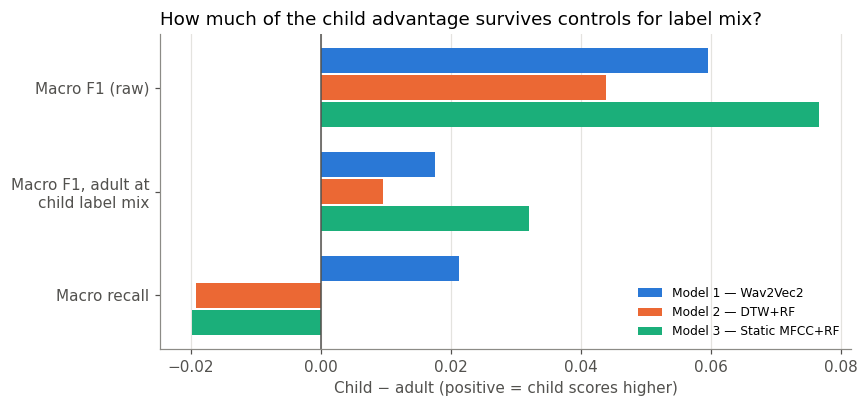

Child − adult macro F1 gap, raw vs after matching the adult label mix to children:
  Model 1 — Wav2Vec2         raw +0.060   matched +0.018   (70% of the raw gap explained by label mix)
  Model 2 — DTW+RF           raw +0.044   matched +0.010   (78% of the raw gap explained by label mix)
  Model 3 — Static MFCC+RF   raw +0.077   matched +0.032   (58% of the raw gap explained by label mix)


In [10]:
measures = ["Macro F1 (raw)", "Macro F1, adult resampled to child label mix",
            "Macro recall (prevalence-invariant)"]
fig, ax = plt.subplots(figsize=(8, 3.8))
y_pos = np.arange(len(measures))
for i, name in enumerate(preds):
    gaps = confound[confound.model == name].set_index("measure").loc[measures, "child_minus_adult"]
    ax.barh(y_pos + (i - 1) * 0.26, gaps, 0.24, color=COLORS[name], label=name)
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_yticks(y_pos, ["Macro F1 (raw)", "Macro F1, adult at\nchild label mix", "Macro recall"])
ax.invert_yaxis()
ax.set_xlabel("Child − adult (positive = child scores higher)")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, fontsize=8, loc="best")
ax.set_title("How much of the child advantage survives controls for label mix?", loc="left")
plt.tight_layout()
plt.savefig(FIG_DIR / "uclass_child_adult_gap_controls.png", dpi=200)
plt.show()

gap = confound.pivot(index="model", columns="measure", values="child_minus_adult")
raw, matched = gap["Macro F1 (raw)"], gap["Macro F1, adult resampled to child label mix"]
print("Child − adult macro F1 gap, raw vs after matching the adult label mix to children:")
for name in preds:
    print(f"  {name:26s} raw {raw[name]:+.3f}   matched {matched[name]:+.3f}   "
          f"({1 - matched[name] / raw[name]:.0%} of the raw gap explained by label mix)")

### Findings

**1. In-corpus (SEP-28k-E test).** Wav2Vec 2.0 reaches macro F1 **0.546** (AUC-ROC 0.849), far
above both MFCC models: +0.393 over the static baseline (paired bootstrap 95% CI [0.370, 0.416],
p < 0.001) and +0.373 over DTW+RF. This supports the hypothesis that pretrained speech
representations beat hand-crafted MFCC features for this task. It is still below the 0.70
"comparable to published benchmarks" bar (Bayerl et al., 2022a); Section 6 of the thesis should
give reasons, e.g. only ~53% of SEP-28k clips could be downloaded, the base rather than large
checkpoint, and single-label majority-vote targets. DTW+RF beats the static baseline by a small but
statistically detectable margin (+0.020, CI [0.003, 0.038], p = 0.025). Keeping temporal structure
helps a little, but both MFCC models sit close to chance (AUC-ROC ≈ 0.55).

**2. Cross-corpus (UCLASS).** Every model degrades sharply. Wav2Vec 2.0 falls to macro F1 0.180
(AUC 0.581), DTW+RF to 0.099 (AUC 0.502), and the static baseline to 0.065 with AUC 0.447, *below*
chance, which means its probability ranking is actively miscalibrated for UCLASS. Wav2Vec 2.0
remains the best model on UCLASS overall and in both age subgroups (all p < 0.001). The domain
shift from podcast audio to clinical recordings dominates model choice, though: no model is
clinically usable cross-corpus.

**3. Imbalance strategy and fine-tuning recipe.** Selection on dev picked **undersampling** for both
RF models. The choice matters for the RFs: the static RF scores 0.115 class-weighted against 0.155
undersampled. For Wav2Vec 2.0, three recipes were tried under each strategy:
- **v1**, the methodology's recipe, overfits within 1–3 epochs.
- **v2** added warmup/decay, a weighted layer sum, augmentation and stronger masking, and stalled
  near chance (dev 0.20–0.26). An ablation traced this to the combination of layer sum, schedule
  and augmentation each slowing early learning (`Model1_Wav2Vec2.ipynb` §5).
- **v3** kept only augmentation, masking and half-epoch dev checks. It overfits much more slowly
  (best checkpoints at epochs 1.4–6 rather than 1–3), but its best dev scores (0.547–0.560) match
  v1's (0.522–0.563).

**v1 + oversampling** was selected. Regularisation changed *when* the model peaks, not *how high*.
That points to the limited training data (about half of SEP-28k is no longer downloadable) or model
capacity as the constraint, rather than overfitting. Differences of about 0.01 between these
configurations are within run-to-run variation.

**4. Child vs adult: the apparent child advantage is mostly a base-rate artefact.** Raw macro F1
is higher on children for every model (+0.044 to +0.077). The two subgroups have very different
label mixes, though: 52% of adult clips are `NoStutteredWords` against 30% of child clips, and
WordRep is only 16 adult clips (0.4%). With that controlled for:
- Resampling adult clips to the child label mix removes **58–78%** of the gap. The remaining
  child–adult difference has overlapping CIs for every model.
- On macro recall, which does not depend on class prevalence, the gap all but disappears: +0.021
  for Wav2Vec 2.0 with heavily overlapping CIs, and slightly *negative* for both RF models.
- A label-blind random predictor that uses each model's own prediction frequencies shows the same
  "child advantage" (+0.046 for DTW+RF vs its raw +0.044; +0.081 for the static RF vs its raw
  +0.077). For the two MFCC models the entire gap is reproduced without looking at the audio.

The data therefore gives **no evidence** that any model generalises better to children's speech.
The child subgroup is also small (<20 speakers), so subgroup conclusions stay exploratory, as the
methodology anticipates.

**5. Per-class.** In-corpus, Interjection (0.70) and NoStutteredWords (0.76) are the easiest
classes for Wav2Vec 2.0 and Block (0.32) the hardest, consistent with blocks being silent or
near-silent events with little acoustic signature. Cross-corpus, WordRep collapses (F1 ≤ 0.08 for
all models), and it has only 54 UCLASS clips in total.